## Stereo and Epipolar Geometry

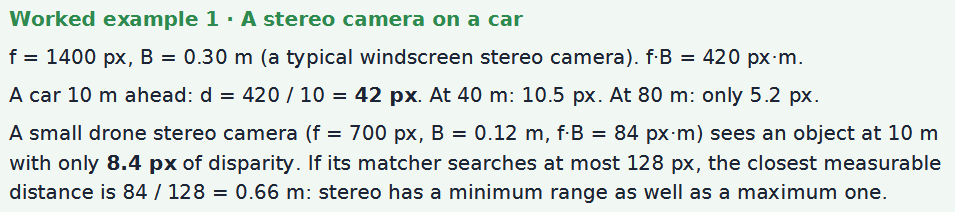

car camera:   f·B = 420 px·m
  object at 10 m -> disparity  42.0 px
  object at 40 m -> disparity  10.5 px
  object at 80 m -> disparity   5.2 px

drone camera: f·B = 84 px·m
  object at 10 m -> disparity 8.4 px
  closest measurable distance (d = 128 px): 0.66 m


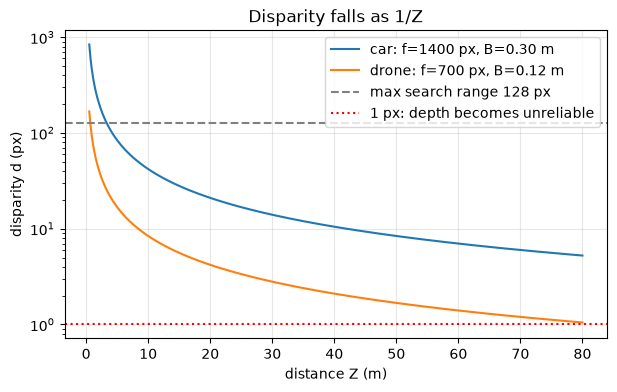

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def disparity_px(f_px, baseline_m, Z_m):
    """Disparity in pixels for an object at depth Z:  d = f·B / Z"""
    return f_px * baseline_m / Z_m

def depth_m(f_px, baseline_m, d_px):
    """Depth from disparity:  Z = f·B / d"""
    return f_px * baseline_m / d_px

# --- car windscreen stereo camera ---
f_car, B_car = 1400, 0.30
print(f"car camera:   f·B = {f_car * B_car:.0f} px·m")
for Z in [10, 40, 80]:
    print(f"  object at {Z:2d} m -> disparity {disparity_px(f_car, B_car, Z):5.1f} px")

# --- small drone stereo camera ---
f_dr, B_dr = 700, 0.12
max_disp = 128                       
print(f"\ndrone camera: f·B = {f_dr * B_dr:.0f} px·m")
print(f"  object at 10 m -> disparity {disparity_px(f_dr, B_dr, 10):.1f} px")
print(f"  closest measurable distance (d = {max_disp} px): {depth_m(f_dr, B_dr, max_disp):.2f} m")

# --- plot: disparity against distance for both cameras ---
Z = np.linspace(0.5, 80, 400)
plt.figure(figsize=(7, 4))
plt.plot(Z, disparity_px(f_car, B_car, Z), label="car: f=1400 px, B=0.30 m")
plt.plot(Z, disparity_px(f_dr, B_dr, Z), label="drone: f=700 px, B=0.12 m")
plt.axhline(max_disp, ls="--", c="gray", label="max search range 128 px")
plt.axhline(1, ls=":", c="red", label="1 px: depth becomes unreliable")
plt.yscale("log")
plt.xlabel("distance Z (m)"); plt.ylabel("disparity d (px)")
plt.title("Disparity falls as 1/Z")
plt.legend(); plt.grid(alpha=0.3); plt.show()

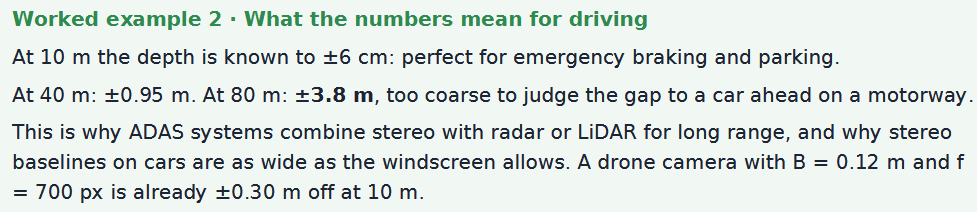

car stereo camera:
  at 10 m: ±0.06 m
  at 40 m: ±0.95 m
  at 80 m: ±3.81 m
drone stereo camera:
  at 10 m: ±0.30 m


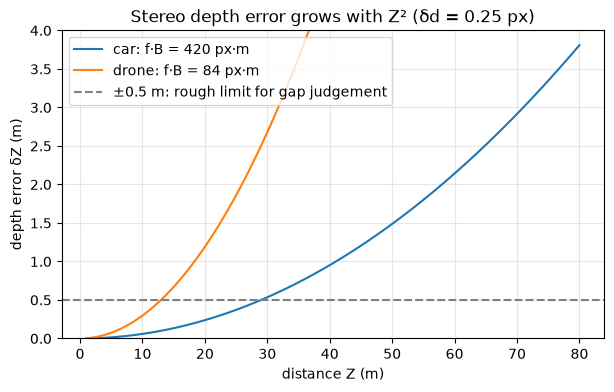

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def depth_error(Z_m, f_px, baseline_m, disp_err_px=0.25):
    """Depth uncertainty of stereo:  δZ = Z² · δd / (f · B)"""
    return Z_m**2 * disp_err_px / (f_px * baseline_m)

f_car, B_car = 1400, 0.30        # car windscreen stereo, f·B = 420 px·m
f_dr,  B_dr  = 700, 0.12         # small drone stereo,    f·B =  84 px·m
dd = 0.25                        # sub-pixel matching error (px)

print("car stereo camera:")
for Z in [10, 40, 80]:
    print(f"  at {Z:2d} m: ±{depth_error(Z, f_car, B_car, dd):.2f} m")
print("drone stereo camera:")
print(f"  at 10 m: ±{depth_error(10, f_dr, B_dr, dd):.2f} m")

# --- plot: depth error grows with Z² ---
Z = np.linspace(1, 80, 400)
plt.figure(figsize=(7, 4))
plt.plot(Z, depth_error(Z, f_car, B_car, dd), label="car: f·B = 420 px·m")
plt.plot(Z, depth_error(Z, f_dr, B_dr, dd), label="drone: f·B = 84 px·m")
plt.axhline(0.5, ls="--", c="gray", label="±0.5 m: rough limit for gap judgement")
plt.xlabel("distance Z (m)"); plt.ylabel("depth error δZ (m)")
plt.title("Stereo depth error grows with Z² (δd = 0.25 px)")
plt.ylim(0, 4); plt.legend(); plt.grid(alpha=0.3); plt.show()

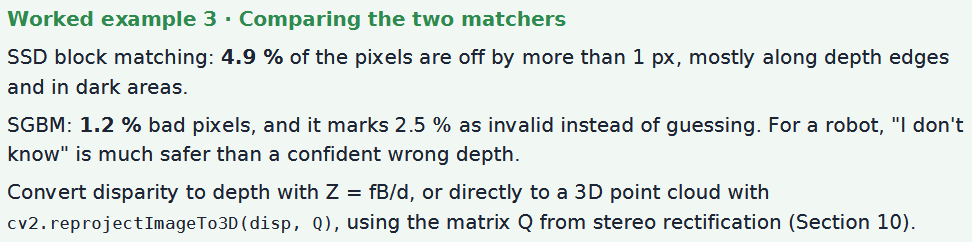

block matching (SSD, 9x9): 4.6% bad pixels (> 1 px)
OpenCV SGBM:               0.8% bad pixels, 2.5% marked invalid

wall (d = 12 px): 4.17 m,  box (d = 40 px): 1.25 m
median SGBM depth on the box: 1.25 m
point cloud: 161416 points
Z from Q equals f·B/d: True


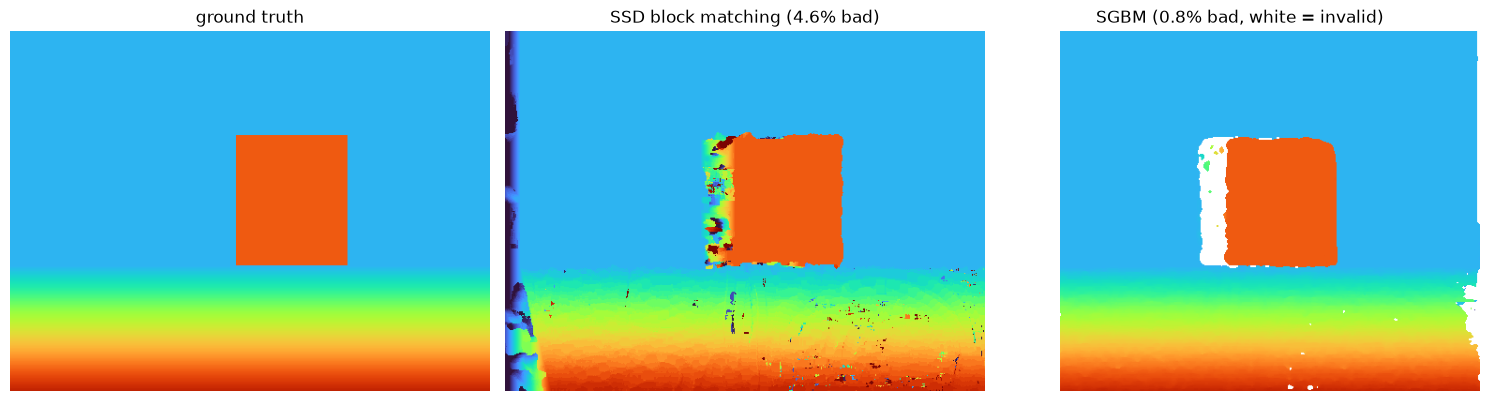

In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data                

# ---------- 1. synthetic rectified stereo pair with known disparity ----------
H, W = 384, 512
tex = cv2.resize(cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2GRAY), (W, H))
rng = np.random.default_rng(0)
tex = np.clip(tex + rng.normal(0, 6, tex.shape), 0, 255).astype(np.uint8)

yy, xx = np.mgrid[0:H, 0:W]
disp_gt = np.full((H, W), 12.0)                              # wall
ground = yy > 250
disp_gt[ground] = 12 + (yy[ground] - 250) * 0.25              # ground comes closer
box = (np.abs(xx - 300) < 60) & (np.abs(yy - 180) < 70)
disp_gt[box] = 40.0                                           # box close to the camera

def render_right(left, disp):
    """Right view: left pixel x appears at x - d; nearer pixels win occlusions."""
    right = np.zeros_like(left)
    zbuf = np.full(left.shape, -1.0)
    xr = np.round(xx - disp).astype(int)
    ok = (xr >= 0) & (xr < W)
    order = np.argsort(disp[ok])                              # far first, near last
    ys, xs, xrs, ds = yy[ok][order], xx[ok][order], xr[ok][order], disp[ok][order]
    right[ys, xrs] = left[ys, xs]
    zbuf[ys, xrs] = ds
    idx = np.maximum.accumulate(np.where(zbuf >= 0, xx, 0), axis=1)  # fill holes
    return right[yy, idx]

left = tex
right = render_right(left, disp_gt)

# ---------- 2. the two matchers ----------
def block_matching(left, right, max_disp=64, win=9):
    """Brute-force SSD block matching along the same row."""
    L, R = left.astype(np.float32), right.astype(np.float32)
    best_cost = np.full(L.shape, np.inf, np.float32)
    best_d = np.zeros(L.shape, np.float32)
    for d in range(max_disp):
        shifted = np.zeros_like(R)
        shifted[:, d:] = R[:, :W - d]
        cost = cv2.boxFilter((L - shifted) ** 2, -1, (win, win))
        better = cost < best_cost
        best_cost[better], best_d[better] = cost[better], d
    return best_d

def bad_pixels(disp, gt, mask, tol=1.0):
    return np.mean(np.abs(disp[mask] - gt[mask]) > tol)

valid = (xx > 70) & (xx < W - 10)                             # skip the image borders
d_bm = block_matching(left, right)

sgbm = cv2.StereoSGBM_create(minDisparity=0, numDisparities=64, blockSize=7,
                             P1=8 * 49, P2=32 * 49, uniquenessRatio=10)
d_sgbm = sgbm.compute(left, right).astype(np.float32) / 16.0  # SGBM returns d x 16
ok = d_sgbm > 0                                               # invalid pixels are negative

bad_bm = bad_pixels(d_bm, disp_gt, valid)
bad_sg = bad_pixels(d_sgbm, disp_gt, valid & ok)
print(f"block matching (SSD, 9x9): {bad_bm:.1%} bad pixels (> 1 px)")
print(f"OpenCV SGBM:               {bad_sg:.1%} bad pixels, "
      f"{np.mean(~ok[valid]):.1%} marked invalid")

# ---------- 3. disparity -> depth:  Z = f·B / d ----------
f_px, B_m = 500.0, 0.10              # assumed camera for this synthetic pair
Z = np.zeros_like(d_sgbm)
Z[ok] = f_px * B_m / d_sgbm[ok]
print(f"\nwall (d = 12 px): {f_px * B_m / 12:.2f} m,  box (d = 40 px): {f_px * B_m / 40:.2f} m")
print(f"median SGBM depth on the box: {np.median(Z[box & ok]):.2f} m")

# ---------- 4. disparity -> 3D point cloud with Q ----------
cx, cy = W / 2, H / 2
Q = np.array([[1, 0, 0, -cx],        # for real cameras, cv2.stereoRectify returns Q
              [0, 1, 0, -cy],
              [0, 0, 0, f_px],
              [0, 0, 1 / B_m, 0]], np.float64)
pts3d = cv2.reprojectImageTo3D(d_sgbm, Q)                     # H x W x 3, metres
cloud = pts3d[ok & valid]
print(f"point cloud: {len(cloud)} points")
print(f"Z from Q equals f·B/d: {np.allclose(pts3d[ok][:, 2], Z[ok])}")

# ---------- 5. show the disparity maps ----------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
maps = [disp_gt, d_bm, np.where(ok, d_sgbm, np.nan)]
titles = ["ground truth", f"SSD block matching ({bad_bm:.1%} bad)",
          f"SGBM ({bad_sg:.1%} bad, white = invalid)"]
for a, m, t in zip(ax, maps, titles):
    a.imshow(m, cmap="turbo", vmin=0, vmax=50); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()